# Arabic Sentiment Analysis with AraBERT
Fine-tune AraBERT v2 on Arabic reviews (negative / neutral / positive), track runs in MLflow, then distill to a 6-layer student.

**Flow:** setup → clean → EDA → split → MLflow check → 5 teacher runs → student → final evaluation.
Part of [Sentiment-Analysis-MLOps](https://github.com/doaa450/Sentiment-Analysis-MLOps). Previous baseline: accuracy 0.7826, F1 macro 0.6537.

## 0. Setup
Install MLflow (same version as the server) and import everything once.

In [1]:
!pip install -q mlflow==3.10.1

import gc
import hashlib
import json
import re

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 21.9 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 81.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 57.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 94.2 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.4/208.4 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.0/77.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.5/231.5 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.2/268.2 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 1. Config
All settings in one place. Change values here only.

In [2]:
PATH = "/kaggle/input/datasets/doaa87/sentiment-analysis/Final_Data.csv"
SOURCE_CSV_PATH = PATH  # raw file, used for the source fingerprint

LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

SEED = 42
MODEL_NAME = "aubmindlab/bert-base-arabertv2"
EPOCHS = 3
EXPERIMENT_NAME = "arabic-sentiment"

# (learning_rate, batch_size) for the 5 teacher runs
RUNS = [(2e-5, 32), (1e-5, 32), (3e-5, 32), (2e-5, 16), (3e-5, 16)]

# Student settings. ALPHA = weight of the hard-label loss
STUDENT_LR, STUDENT_EPOCHS, STUDENT_BS = 5e-5, 4, 32
STUDENT_CONFIGS = [(0.5, 2.0)]  # (alpha, temperature); add (0.4, 4.0) for a second run

## 2. Load & clean
Drop missing rows, remove URLs and Arabic diacritics, drop empty and duplicate reviews, map labels to ids.

In [3]:
URL = re.compile(r"https?://\S+")
DIAC = re.compile(r"[\u064B-\u0652\u0640]")


def clean_text(t):
    t = URL.sub(" ", t)
    t = DIAC.sub("", t)
    return re.sub(r"\s+", " ", t).strip()


raw = pd.read_csv(PATH)
df = raw.dropna(subset=["review_description", "rating"]).copy()
df["text"] = df["review_description"].astype(str).map(clean_text)
df = df[df["text"].str.len() > 0].drop_duplicates("text")
df["label_name"] = df["rating"].str.strip().str.lower()
df["label"] = df["label_name"].map(LABEL2ID)
df = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)
df["n_words"] = df["text"].str.split().str.len()
print(len(raw), "->", len(df))

40046 -> 38814


## 3. EDA
Class balance, review length, top companies, label mix per company.

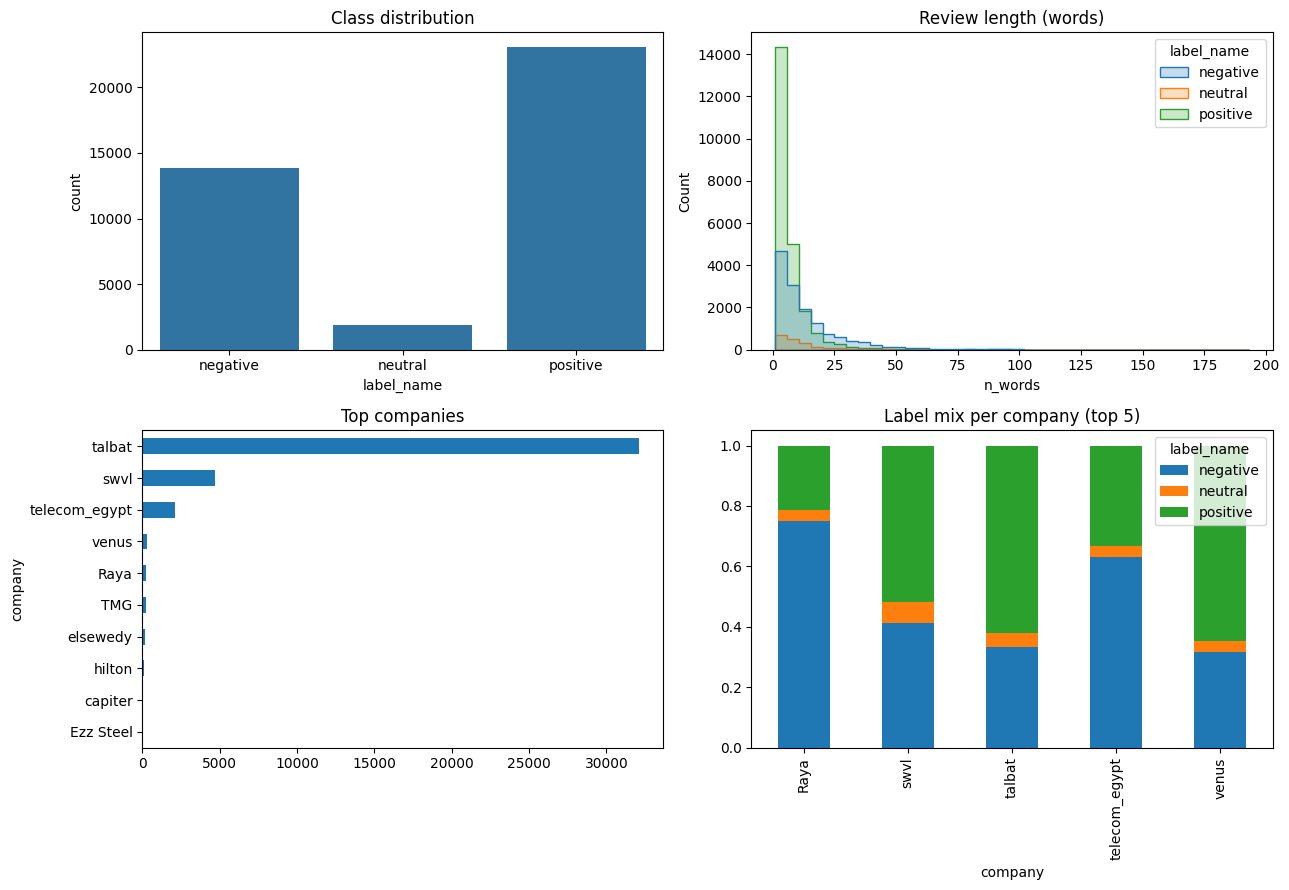

In [4]:
order = ["negative", "neutral", "positive"]
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(x=df["label_name"], order=order, ax=ax[0, 0])
ax[0, 0].set_title("Class distribution")

sns.histplot(data=df[df["n_words"] < 200], x="n_words", hue="label_name",
             hue_order=order, bins=40, element="step", ax=ax[0, 1])
ax[0, 1].set_title("Review length (words)")

raw["company"].value_counts().head(10).plot.barh(ax=ax[1, 0])
ax[1, 0].invert_yaxis()
ax[1, 0].set_title("Top companies")

top = df["company"].value_counts().head(5).index
sub = df[df["company"].isin(top)]
pd.crosstab(sub["company"], sub["label_name"], normalize="index").plot.bar(
    stacked=True, ax=ax[1, 1])
ax[1, 1].set_title("Label mix per company (top 5)")

plt.tight_layout()
plt.savefig("/kaggle/working/eda.png", dpi=120)
plt.show()

## 4. Split, fingerprints, class weights
80/20 stratified split. MD5 fingerprints of the raw file and both splits are saved as MLflow tags. Class weights help the small neutral class.

In [5]:
def file_md5(path, chunk_size=1024 * 1024):
    """MD5 of a file (same method DVC uses)."""
    md5 = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            md5.update(chunk)
    return md5.hexdigest()


def df_md5(d):
    """MD5 of a DataFrame's content (row order matters)."""
    return hashlib.md5(pd.util.hash_pandas_object(d, index=False).values.tobytes()).hexdigest()


train_df, val_df = train_test_split(
    df, test_size=0.2, stratify=df["label"], random_state=SEED
)

FINGERPRINTS = {
    "source_data_md5": file_md5(SOURCE_CSV_PATH),
    "train_data_md5": df_md5(train_df),
    "val_data_md5": df_md5(val_df),
}
print(FINGERPRINTS)

weights = compute_class_weight(
    "balanced", classes=np.arange(3), y=train_df["label"].values
)
print("train/val:", len(train_df), len(val_df), "| class weights:", weights.round(2))

{'source_data_md5': '77573994194612e9e216e3466b2eeb42', 'train_data_md5': '1db388e85b2afed53e2c7b535b89c3c7', 'val_data_md5': 'bedc63ad4bb60015cfa770d5a5984853'}
train/val: 31051 7763 | class weights: [0.93 6.9  0.56]


## 5. Connect to MLflow
The URL comes from the Kaggle Secret `MLFLOW_TRACKING_URI` (your ngrok link). The assert stops the run early if the URL is wrong, so nothing is logged to a local folder by mistake.

In [6]:
from kaggle_secrets import UserSecretsClient

uri = UserSecretsClient().get_secret("MLFLOW_TRACKING_URI").strip()
assert uri.startswith("https://"), f"Bad tracking URI (starts with: {uri[:8]!r})"
mlflow.set_tracking_uri(uri)
mlflow.set_experiment(EXPERIMENT_NAME)
print([e.name for e in mlflow.search_experiments()])

2026/10/20 01:41:58 INFO mlflow.tracking.fluent: Experiment with name 'arabic-sentiment' does not exist. Creating a new experiment.


['arabic-sentiment', 'Default']


## 6a. Tokenizer, datasets, trainer
Tokenize once and reuse for all runs. `WeightedTrainer` uses class-weighted loss. `compute_metrics` also returns the neutral F1.

In [7]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)


class DS(torch.utils.data.Dataset):
    def __init__(self, d):
        self.enc = tok(d["text"].tolist(), truncation=True, max_length=128)
        self.y = d["label"].tolist()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return {**{k: v[i] for k, v in self.enc.items()}, "labels": self.y[i]}


train_ds, val_ds = DS(train_df), DS(val_df)
data_collator = DataCollatorWithPadding(tok)


class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        out = model(**inputs)
        loss = torch.nn.CrossEntropyLoss(
            weight=torch.tensor(weights, dtype=torch.float).to(out.logits.device)
        )(out.logits, labels)
        return (loss, out) if return_outputs else loss


def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {
        "accuracy": accuracy_score(p.label_ids, preds),
        "macro_f1": f1_score(p.label_ids, preds, average="macro"),
        "f1_neutral": f1_score(p.label_ids, preds, labels=[1], average="macro"),
    }


def make_args(out_dir, lr, bs, epochs):
    return TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=bs,
        per_device_eval_batch_size=64,
        learning_rate=lr,
        eval_strategy="epoch",
        save_strategy="no",
        seed=SEED,
        fp16=torch.cuda.is_available(),
        report_to="none",
    )

config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/611 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/720k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

## 6b. Baseline check
Evaluate the model already published on HF on the same validation split and log it to MLflow (evaluation only, not a training run).

In [8]:
# Baseline: model already published on HF (used by the API), evaluation only
baseline_model = AutoModelForSequenceClassification.from_pretrained("DoaaMoh/arabert-sentiment")
baseline_trainer = Trainer(
    model=baseline_model,
    args=TrainingArguments(
        output_dir="/kaggle/working/runs/baseline",
        per_device_eval_batch_size=64,
        fp16=torch.cuda.is_available(),
        report_to="none",
    ),
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=tok,
)
baseline_metrics = baseline_trainer.evaluate(val_ds)

with mlflow.start_run(run_name="baseline"):
    mlflow.set_tags({**FINGERPRINTS, "stage": "baseline", "note": "already trained, evaluation only"})
    mlflow.log_params({"model_name": "DoaaMoh/arabert-sentiment", "lr": 2e-5, "batch_size": 32})
    mlflow.log_metrics({
        "accuracy": baseline_metrics["eval_accuracy"],
        "f1_macro": baseline_metrics["eval_macro_f1"],
        "f1_neutral": baseline_metrics["eval_f1_neutral"],
    })
print(baseline_metrics)

# Free GPU memory before the teacher runs
del baseline_model, baseline_trainer
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/850 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Step,Accuracy,Macro F1,F1 Neutral
No log,1.104765,0,0.782558,0.653662,0.285373


🏃 View run baseline at: https://87ba-41-39-41-234.ngrok-free.app/#/experiments/1/runs/1f07ea78b7a84b1cb5db30bd132182d2
🧪 View experiment at: https://87ba-41-39-41-234.ngrok-free.app/#/experiments/1
{'eval_loss': 1.1047648191452026, 'eval_accuracy': 0.7825582893211387, 'eval_macro_f1': 0.653661702620291, 'eval_f1_neutral': 0.2853731343283582}


In [9]:
r = mlflow.get_run("1f07ea78b7a84b1cb5db30bd132182d2")
print(r.data.metrics)

{'accuracy': 0.7825582893211387, 'f1_macro': 0.653661702620291, 'f1_neutral': 0.2853731343283582}


## 7. Teacher: 5 runs
One MLflow run per (lr, batch size). The best run by F1 macro is saved to `best_model`. Takes the longest, keep the laptop, Docker and ngrok running.

In [10]:
def train_one_run(lr, bs, run_name):
    set_seed(SEED)  # before model creation (random classifier head)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID
    )
    trainer = WeightedTrainer(
        model=model,
        args=make_args(f"/kaggle/working/runs/{run_name}", lr, bs, EPOCHS),
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        processing_class=tok,
    )
    trainer.train()
    return trainer, trainer.evaluate()


best_f1, best_run_name = 0.0, None
results = []

for lr, bs in RUNS:
    run_name = f"lr{lr}_bs{bs}"
    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags({**FINGERPRINTS, "stage": "teacher"})
        mlflow.log_params({
            "model_name": MODEL_NAME, "lr": lr, "batch_size": bs,
            "epochs": EPOCHS, "seed": SEED,
            "split_test_size": 0.2, "split_seed": SEED,
        })

        trainer, m = train_one_run(lr, bs, run_name)
        acc, f1, f1n = m["eval_accuracy"], m["eval_macro_f1"], m["eval_f1_neutral"]
        mlflow.log_metrics({"accuracy": acc, "f1_macro": f1, "f1_neutral": f1n})
        results.append({"run": run_name, "lr": lr, "batch_size": bs,
                        "accuracy": acc, "f1_macro": f1, "f1_neutral": f1n})

        if f1 > best_f1:  # new best: overwrite the saved teacher
            best_f1, best_run_name = f1, run_name
            trainer.save_model("best_model")
            tok.save_pretrained("best_model")

    del trainer
    gc.collect()
    torch.cuda.empty_cache()

print(pd.DataFrame(results).sort_values("f1_macro", ascending=False).to_string(index=False))
print(f"BEST: {best_run_name}  f1_macro={best_f1:.4f}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  543MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transfor

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,F1 Neutral
1,No log,0.673588,0.774056,0.643137,0.263095
2,0.769275,0.685743,0.792735,0.655276,0.281879
3,0.631214,0.679105,0.776633,0.647146,0.269805


...

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transfor

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,F1 Neutral
1,0.800549,0.675629,0.764910,0.638023,0.256971
2,0.619927,0.717194,0.807291,0.655943,0.267776
3,0.527719,0.773018,0.811413,0.662709,0.280564


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,F1 Neutral
0.527719,0.773018,3,0.811413,0.662709,0.280564


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

🏃 View run lr3e-05_bs16 at: https://87ba-41-39-41-234.ngrok-free.app/#/experiments/1/runs/00351fbd23654dafb550cd64ffa4204d
🧪 View experiment at: https://87ba-41-39-41-234.ngrok-free.app/#/experiments/1
         run      lr  batch_size  accuracy  f1_macro  f1_neutral
lr3e-05_bs16 0.00003          16  0.811413  0.662709    0.280564
lr2e-05_bs16 0.00002          16  0.804328  0.656689    0.269713
lr3e-05_bs32 0.00003          32  0.784104  0.651120    0.273671
lr2e-05_bs32 0.00002          32  0.776633  0.647146    0.269805
lr1e-05_bs32 0.00001          32  0.758985  0.633295    0.259684
BEST: lr3e-05_bs16  f1_macro=0.6627


## 8. Student: distillation
6-layer student, initialised from every 2nd teacher layer. Loss = alpha × hard-label CE + (1 − alpha) × KL to the teacher (softened by temperature, scaled by T²). Needs `best_model` from section 7.

In [11]:
class DistillTrainer(Trainer):
    def __init__(self, *args, teacher=None, alpha=0.5, temperature=2.0, **kwargs):
        super().__init__(*args, **kwargs)
        self.teacher = teacher.to(self.args.device).eval()
        for p in self.teacher.parameters():
            p.requires_grad_(False)
        self.alpha, self.T = alpha, temperature

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        out = model(**inputs)
        with torch.no_grad():
            t_logits = self.teacher(**inputs).logits

        # Hard-label loss (same class weights as the teacher)
        ce = F.cross_entropy(
            out.logits, labels,
            weight=torch.tensor(weights, dtype=torch.float).to(out.logits.device),
        )
        # Soft-label loss: student mimics the teacher's softened probabilities
        kd = F.kl_div(
            F.log_softmax(out.logits / self.T, dim=-1),
            F.softmax(t_logits / self.T, dim=-1),
            reduction="batchmean",
        ) * (self.T ** 2)

        loss = self.alpha * ce + (1 - self.alpha) * kd
        return (loss, out) if return_outputs else loss


def build_student(teacher_dir="best_model", n_layers=6):
    """6-layer student initialised from every 2nd layer of the teacher."""
    teacher = AutoModelForSequenceClassification.from_pretrained(teacher_dir)
    cfg = AutoConfig.from_pretrained(teacher_dir)
    cfg.num_hidden_layers = n_layers
    student = AutoModelForSequenceClassification.from_config(cfg)

    student.bert.embeddings.load_state_dict(teacher.bert.embeddings.state_dict())
    t_layers = list(range(0, teacher.config.num_hidden_layers, 2))[:n_layers]  # 0,2,4,6,8,10
    for s_i, t_i in enumerate(t_layers):
        student.bert.encoder.layer[s_i].load_state_dict(
            teacher.bert.encoder.layer[t_i].state_dict()
        )
    student.bert.pooler.load_state_dict(teacher.bert.pooler.state_dict())
    student.classifier.load_state_dict(teacher.classifier.state_dict())
    return teacher, student


best_student_f1 = 0.0
student_results = []

for alpha, temp in STUDENT_CONFIGS:
    run_name = f"student_a{alpha}_t{temp}"
    set_seed(SEED)
    teacher, student = build_student()
    n_params = sum(p.numel() for p in student.parameters())

    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags({**FINGERPRINTS, "stage": "distilled", "teacher_run": best_run_name})
        mlflow.log_params({
            "model_name": MODEL_NAME, "lr": STUDENT_LR, "batch_size": STUDENT_BS,
            "epochs": STUDENT_EPOCHS, "seed": SEED, "num_layers": 6,
            "alpha": alpha, "temperature": temp,
            "student_params_millions": round(n_params / 1e6, 1),
        })

        s_trainer = DistillTrainer(
            teacher=teacher, alpha=alpha, temperature=temp,
            model=student,
            args=make_args("/kaggle/working/runs/student", STUDENT_LR, STUDENT_BS, STUDENT_EPOCHS),
            train_dataset=train_ds,
            eval_dataset=val_ds,
            data_collator=data_collator,
            compute_metrics=compute_metrics,
            processing_class=tok,
        )
        s_trainer.train()
        sm = s_trainer.evaluate()
        mlflow.log_metrics({
            "accuracy": sm["eval_accuracy"],
            "f1_macro": sm["eval_macro_f1"],
            "f1_neutral": sm["eval_f1_neutral"],
        })
        student_results.append({"run": run_name, "accuracy": sm["eval_accuracy"],
                                "f1_macro": sm["eval_macro_f1"], "f1_neutral": sm["eval_f1_neutral"]})

        if sm["eval_macro_f1"] > best_student_f1:  # keep the best student
            best_student_f1 = sm["eval_macro_f1"]
            s_trainer.save_model("student_model")
            tok.save_pretrained("student_model")

    del s_trainer, teacher, student
    gc.collect()
    torch.cuda.empty_cache()

print(pd.DataFrame(student_results).to_string(index=False))
print(f"TEACHER (best): f1_macro={best_f1:.4f} | STUDENT (best): f1_macro={best_student_f1:.4f}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,F1 Neutral
1,No log,0.414464,0.783460,0.648195,0.271207
2,0.449745,0.433148,0.797887,0.654882,0.273171
3,0.328377,0.440761,0.806003,0.657574,0.273717
4,0.264056,0.459245,0.812572,0.655562,0.261383


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,F1 Neutral
0.264056,0.459245,4,0.812572,0.655562,0.261383


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

🏃 View run student_a0.5_t2.0 at: https://87ba-41-39-41-234.ngrok-free.app/#/experiments/1/runs/56afdd3d24124ed8af2ae442960b58bc
🧪 View experiment at: https://87ba-41-39-41-234.ngrok-free.app/#/experiments/1
              run  accuracy  f1_macro  f1_neutral
student_a0.5_t2.0  0.812572  0.655562    0.261383
TEACHER (best): f1_macro=0.6627 | STUDENT (best): f1_macro=0.6556


## 9. Final evaluation of the best teacher
Evaluate `best_model` on the validation set (not the last run). Saves `metrics.json`.

In [12]:
best = AutoModelForSequenceClassification.from_pretrained("best_model")
eval_trainer = Trainer(
    model=best,
    args=TrainingArguments(
        output_dir="/kaggle/working/runs/eval",
        per_device_eval_batch_size=64,
        fp16=torch.cuda.is_available(),
        report_to="none",
    ),
    data_collator=data_collator,
    processing_class=tok,
)
pred = eval_trainer.predict(val_ds)
y_true, y_pred = pred.label_ids, pred.predictions.argmax(-1)

report = classification_report(y_true, y_pred, target_names=list(LABEL2ID), output_dict=True)
overall = {
    "accuracy": accuracy_score(y_true, y_pred),
    "f1_macro": report["macro avg"]["f1-score"],
    "f1_weighted": report["weighted avg"]["f1-score"],
}
per_class = {
    n: {"precision": report[n]["precision"], "recall": report[n]["recall"],
        "f1": report[n]["f1-score"], "support": int(report[n]["support"])}
    for n in LABEL2ID
}
with open("/kaggle/working/metrics.json", "w") as f:
    json.dump({"overall": overall, "per_class": per_class}, f, indent=2)

print(overall)
print(classification_report(y_true, y_pred, target_names=list(LABEL2ID)))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'accuracy': 0.811413113487054, 'f1_macro': 0.6627085074436402, 'f1_weighted': 0.8312558124861986}
              precision    recall  f1-score   support

    negative       0.85      0.81      0.83      2778
     neutral       0.20      0.48      0.28       375
    positive       0.92      0.84      0.88      4610

    accuracy                           0.81      7763
   macro avg       0.66      0.71      0.66      7763
weighted avg       0.86      0.81      0.83      7763



## 10. What's next
Click **Save Version**, then download `best_model/` and `student_model/` from the Output tab. Pushing to Hugging Face and registering in MLflow are separate steps after we compare the runs.

## 10. Publish to Hugging Face
Upload the best teacher and the student to the Hub, and print the SHA-256 of each model file for the README.

In [13]:
import hashlib
import os

from huggingface_hub import HfApi
from kaggle_secrets import UserSecretsClient

api = HfApi(token=UserSecretsClient().get_secret("HF_TOKEN"))

REPOS = {
    "best_model": "DoaaMoh/arabert-sentiment-v2",
    "student_model": "DoaaMoh/arabert-sentiment-student",
}


def sha256_of(path, chunk=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


for folder, repo_id in REPOS.items():
    print(folder, "->", sorted(os.listdir(folder)))
    weights_file = os.path.join(folder, "model.safetensors")
    print("SHA-256:", sha256_of(weights_file))

    api.create_repo(repo_id, exist_ok=True)  # public by default
    api.upload_folder(folder_path=folder, repo_id=repo_id,
                      commit_message=f"Upload {folder}")
    print("uploaded:", f"https://huggingface.co/{repo_id}")

best_model -> ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']
SHA-256: bd184466583c47f18a30985f8fdf32f520bdb87da4eafb21249c3904b8fd3157
uploaded: https://huggingface.co/DoaaMoh/arabert-sentiment-v2
student_model -> ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']
SHA-256: 0f328703bc04e9597de6f6230aded01244e2fbc362d9cc0506e9181f48bc4d32
uploaded: https://huggingface.co/DoaaMoh/arabert-sentiment-student
